In [1]:
import numpy as np
import pandas as pd

In [2]:
from sklearn.datasets import load_breast_cancer

In [3]:
cancer = load_breast_cancer()

In [4]:
df = pd.DataFrame(cancer.data, columns= cancer.feature_names)

In [5]:
df['target'] = cancer.target

In [6]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [7]:
df.shape

(569, 31)

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, :-1], df.iloc[:, -1], test_size= 0.2, random_state= 42)

In [10]:
from sklearn.preprocessing import StandardScaler

In [11]:
scaler = StandardScaler()

In [12]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [13]:
from sklearn.neighbors import KNeighborsClassifier

In [14]:
knn = KNeighborsClassifier(n_neighbors= 5)

In [15]:
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [16]:
from sklearn.metrics import accuracy_score

In [17]:
accuracy_score(y_test, knn.predict(X_test))

0.9473684210526315

In [18]:
# experimenting with different k values

In [28]:
accuracy_scores = []
for k in range(1, 16):
    knn = KNeighborsClassifier(k)
    knn.fit(X_train, y_train)
    accuracy_scores.append(accuracy_score(y_test, knn.predict(X_test)))

accuracy_scores = np.array(accuracy_scores)

In [30]:
best = np.argmax(accuracy_scores)
print(best)
print(np.max(accuracy_scores))

8
0.9649122807017544


In [31]:
# doing this for iris data and plotting the decision boundary

In [32]:
from sklearn.datasets import load_iris

In [33]:
iris = load_iris()

In [34]:
df = pd.DataFrame(iris.data, columns= iris.feature_names)

In [44]:
df['target'] = iris.target_names[iris.target]

In [45]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [46]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [49]:
df['target'] = iris.target

In [50]:
import matplotlib.pyplot as plt

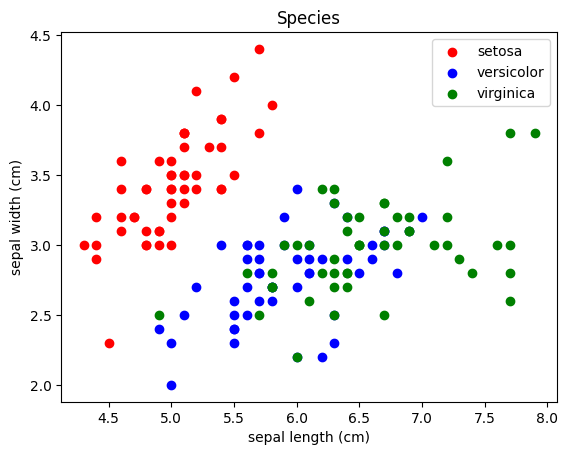

In [51]:
color = ['red', 'blue', 'green']
labels = ['setosa', 'versicolor', 'virginica']
for i in range(3):
    subset = df[df['target'] == i]
    plt.scatter(subset['sepal length (cm)'], subset['sepal width (cm)'], color = color[i], label = labels[i])
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.title('Species')
plt.legend()

In [52]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, :2], df.iloc[:, -1], test_size= 0.2, random_state= 42)

In [54]:
knn = KNeighborsClassifier(5)
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [55]:
x_min, x_max = df.iloc[:, 0].min() - 1, df.iloc[:, 0].max() + 1
y_min, y_max = df.iloc[:, 1].min() - 1, df.iloc[:, 1].max() + 1

In [56]:
x = np.arange(x_min, x_max, 0.01)
y = np.arange(y_min, y_max, 0.01)

In [57]:
xx, yy = np.meshgrid(x, y)

In [58]:
xx.shape

(440, 560)

In [59]:
yy.shape

(440, 560)

In [60]:
z = knn.predict(np.c_[xx.ravel(), yy.ravel()])

C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [61]:
z.shape

(246400,)

In [62]:
z = z.reshape(xx.shape)

In [64]:
z.shape

(440, 560)

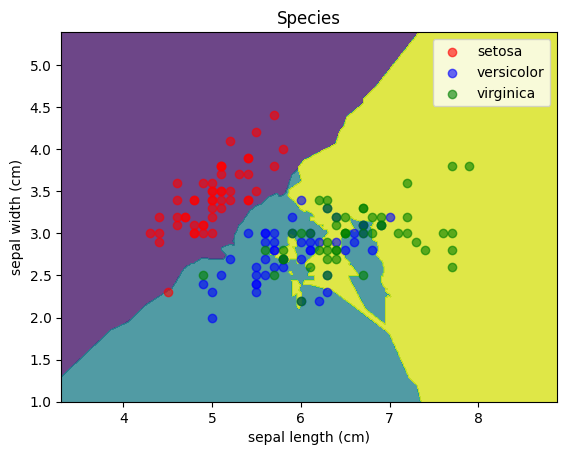

In [69]:
plt.contourf(xx, yy, z, alpha = 0.8)
color = ['red', 'blue', 'green']
labels = ['setosa', 'versicolor', 'virginica']
for i in range(3):
    subset = df[df['target'] == i]
    plt.scatter(subset['sepal length (cm)'], subset['sepal width (cm)'], color = color[i], label = labels[i], alpha = 0.6)
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.title('Species')
plt.legend()